CNNs anf GNNs as classifiers for sparse data events


**Tasks:** <p>
Jet tagging (e.g. classification of jets originating from different particles: *gluons, quarks, Ws, Zs, and top quarks*).

**Physics context:** <p>
At the extreme energies of the Large Hadron Collider, massive particles can be produced with such high Lorentz boost that their decays into hadrons (hadron jets) are collimated in such a way that the resulting particles overlap. Deducing whether the substructure of an observed jet is due to a single low-mass particle or to multiple decay objects of a high-mass particle is an important problem in LHC data analysis. Traditional approaches are based on high-level observables built from theoretical models of energy deposition in calorimeters and charged tracks parameters reconsrtcuted in the inner tracker, but the complexity of the data makes this task an excellent candidate for the application of deep learning tools. The jet constituents can be in fact represented either as 2D or ND images,lending itself to the natural application of image classification techniques (CNN, ViT etc.), or as pointclouds/graphs, that can be classified with GNNs, or also as sequences, that can be analysed by RNNs or Transformers.

1.   create image-like and graph-like structures to represent jets from decays of different particles at an hadron collider using the *JetDataset*
2.   design and train a CNN architecture to classify jet image in one of the 5 categories: jet from [g,q,W,Z,t]
3.   assess performances of the trained model

In [1]:
#imports
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import glob

## Dataset:
The problem consists in identifying a given jet as a quark, a gluon, a W, a Z, or a top, based either on a **jet image**, i.e., a **2D histogram of the transverse momentum ($p_T$) deposited in each of 100x100 bins of a square window of the ($\eta,\phi$) plane, centered along the jet axis**

The jet constituents are stored in the **features** numpy array of shape (20000,100,16), where 100 is the number of jet constituents (if smaller than 100 is zero-padded to 100, if larger si trimmed to 100). and 16 is the number of features associated to each particle:

* the four-momentum in cartesian coordinates $(p_x,p_y,p_z,E)$
* the energy divided by the jet energy ($E_{rel}$)
* the transverse momentum ($p_T$), i.e. the momentum projected on the plane transverse to proton beams
* the momentum transverse to the jet direction ($p_{Trel}$)
* the pseudorapidity ($\eta$), a function of the polar angle (see https://en.wikipedia.org/wiki/Pseudorapidity)
* the pseudorapidity relative to the jet direction ($\eta_{rel}$)
* the pseudorapidity relative to the jet direction ($\eta_{rot}$) after a rotation is applied so that the jet image looks vertical
* the azimuth angle ($\phi$)
* the azimuth angle relative to the jet direction ($\phi_{rel}$)
* the azimuth angle relative to the jet direction ($\phi_{rot}$) after a rotation is applied so that the jet image looks vertical
* the $\Delta R = \sqrt{(\Delta\eta_{max})^2 + (\Delta\phi_{max})^2}$ of the jet
* the $\cos\theta$ of the jet
* the $\cos\theta_{rel}$ of the jet

The ground truth is incorporated in a **target** (['j_g', 'j_q', 'j_w', 'j_z', 'j_t]) numpy array of boolean with shape (20000,5) encoding the labels such that:

* $[1, 0, 0, 0, 0]$ for gluons
* $[0, 1, 0, 0, 0]$ for quarks
* $[0, 0, 1, 0, 0]$ f
or W bosons (with W -> qq)
* $[0, 0, 0, 1, 0]$ for Z bosons (with Z -> qq)
* $[0, 0, 0, 0, 1]$ for top quarks (with t -> Wq -> qqq)

This is what is called 'one-hot' encoding of a discrete label (typical of ground truth for classification problems).

In [2]:
# read dataset
with np.load('dataset_jetTag.npz') as f:
  print(f.files)
  target = f['target']
  features = f['features']

# convert one-hot lables in integers labels
label = np.argmax(target, axis=1)

print(target.shape, label.shape, features.shape)

['target', 'features']
(20000, 5) (20000,) (20000, 100, 16)


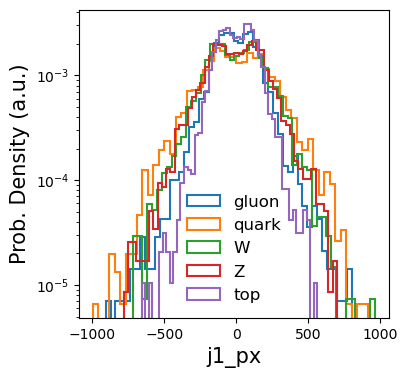

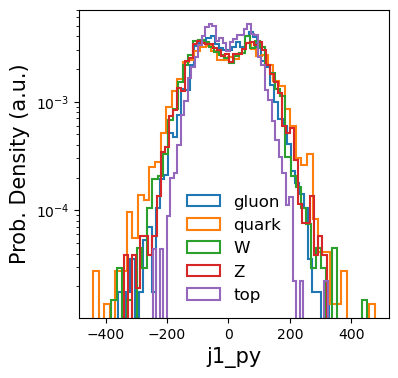

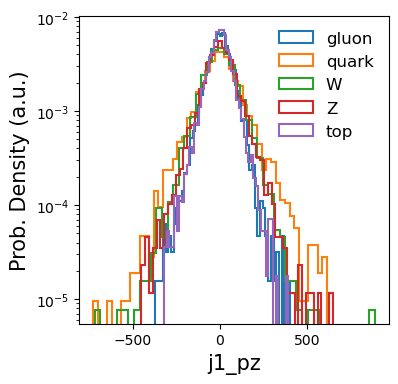

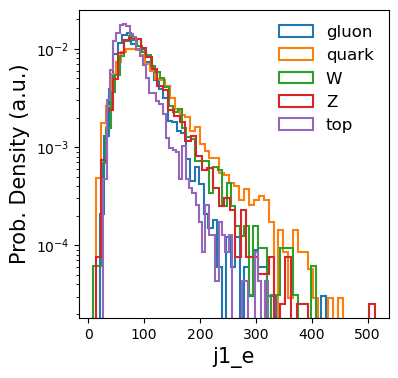

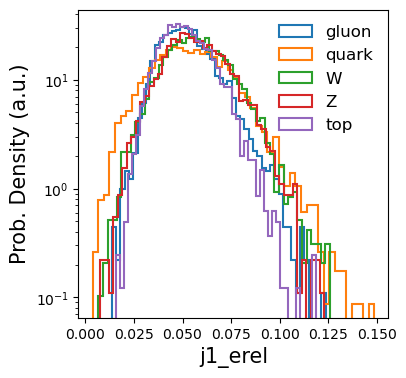

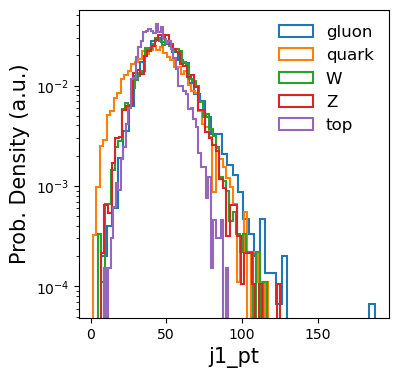

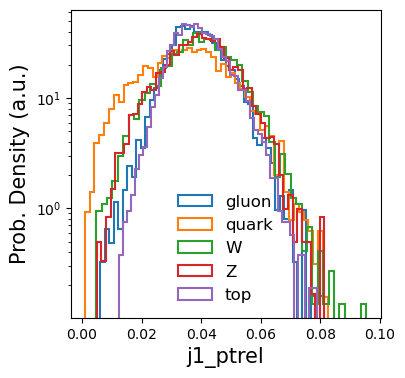

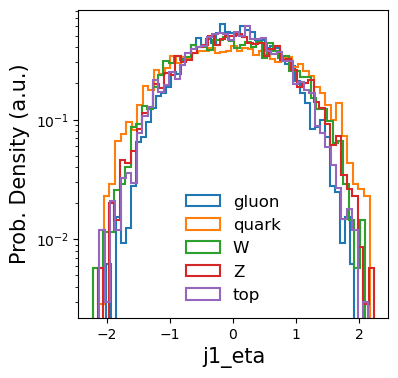

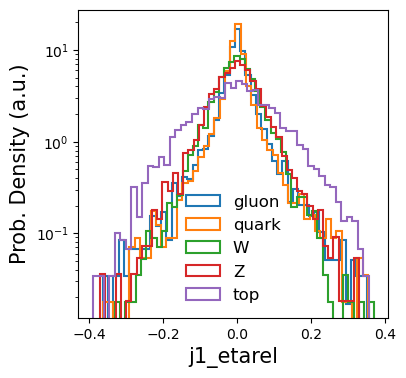

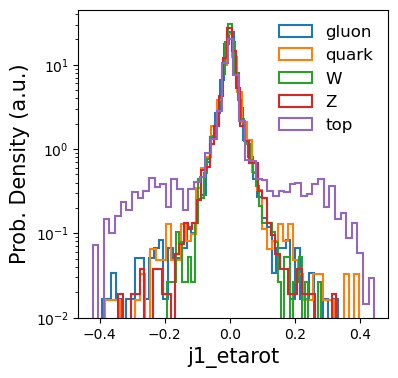

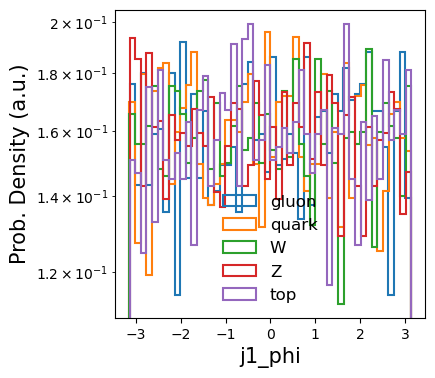

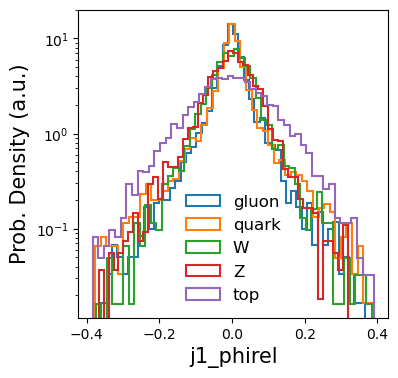

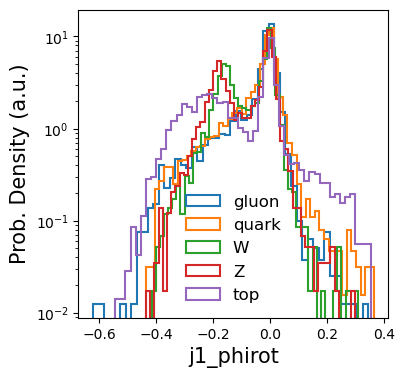

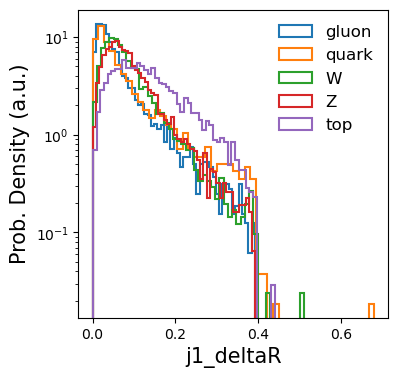

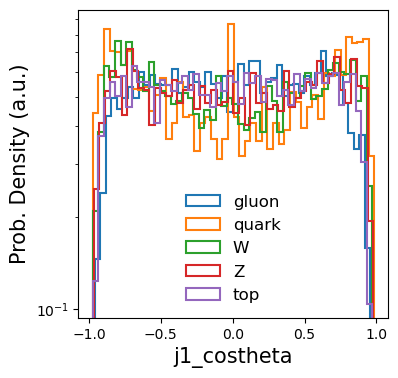

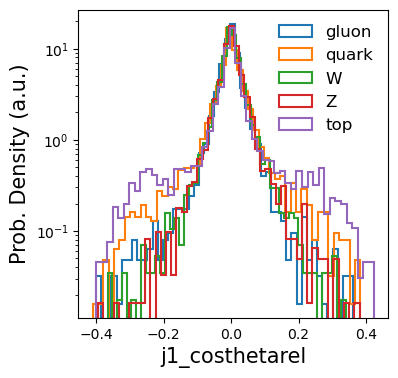

In [3]:
# plot of the features:

# this function makes the histogram of a given quantity for the five classes
def makePlot_p(feature_index, input_data, input_featurenames, labels):
    plt.subplots(figsize=(4,4))
    for i in range(len(labels)):
        my_data = input_data[:,:,feature_index]
        # notice the use of numpy masking to select specific classes of jets
        my_data = my_data[np.argmax(target, axis=1) == i]
        # then plot the right quantity for the reduced array
        plt.hist(my_data[:,feature_index].flatten(), 50, density=True, histtype='step', fill=False, linewidth=1.5)
    plt.yscale('log', nonpositive='clip', )
    plt.legend(labels, fontsize=12, frameon=False)
    plt.xlabel(input_featurenames[feature_index], fontsize=15)
    plt.ylabel('Prob. Density (a.u.)', fontsize=15)
    plt.show()

featurenames = ['j1_px','j1_py','j1_pz','j1_e','j1_erel','j1_pt','j1_ptrel',
 'j1_eta','j1_etarel','j1_etarot','j1_phi','j1_phirel','j1_phirot',
 'j1_deltaR','j1_costheta','j1_costhetarel']

labels_str = ['gluon', 'quark', 'W', 'Z', 'top']

# we now plot all the features
for i in range(len(featurenames)):
    makePlot_p(i, features, featurenames, labels_str)

In [4]:
# create jet "images": eg project each particle $p_T$ in a 100x100 eta,phi grid ceneterd around the jet direction
def create_images(features):
    jet_imgs = np.empty((features.shape[0],100,100))

    for i in range(features.shape[0]):
      eta = features[i,:,8]
      phi = features[i,:,11]
      pt = features[i,:,5]
      h,_,_ = np.histogram2d(eta,phi,bins=100,range=[[-1,1],[-1,1]], weights=pt)
      jet_imgs[i] = h

    return jet_imgs
# split in train, validation and test sets
from sklearn.model_selection import train_test_split

# Split into training and remaining dataset
X_train, X_rem, y_train, y_rem = train_test_split(features, label, train_size=0.8)
X_valid, X_test, y_valid, y_test = train_test_split(X_rem,y_rem, test_size=0.5)

print(X_train.shape), print(y_train.shape)
print(X_valid.shape), print(y_valid.shape)
print(X_test.shape), print(y_test.shape)

jet_imgs_train = create_images(X_train)
jet_imgs_valid = create_images(X_valid)
jet_imgs_test = create_images(X_test)


(16000, 100, 16)
(16000,)
(2000, 100, 16)
(2000,)
(2000, 100, 16)
(2000,)


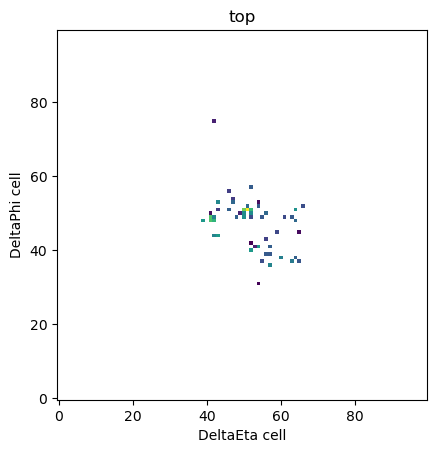

In [5]:
# print one jet image
# plot a single image to display the sparsity
from matplotlib.colors import LogNorm
def plot_single_image(jet_imgs,label,i=1):
    plt.imshow(jet_imgs[i], origin='lower',norm=LogNorm())
    plt.title(labels_str[label[i]])
    plt.xlabel('DeltaEta cell')
    plt.ylabel('DeltaPhi cell')
    plt.show()
plot_single_image(jet_imgs_train,y_train,i=1022)

In [6]:
jet_imgs_train[0].shape

(100, 100)

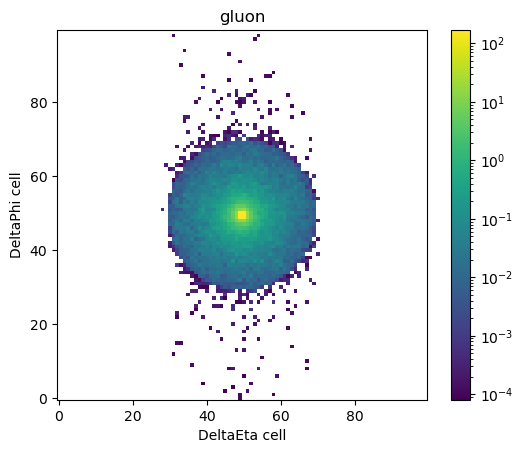

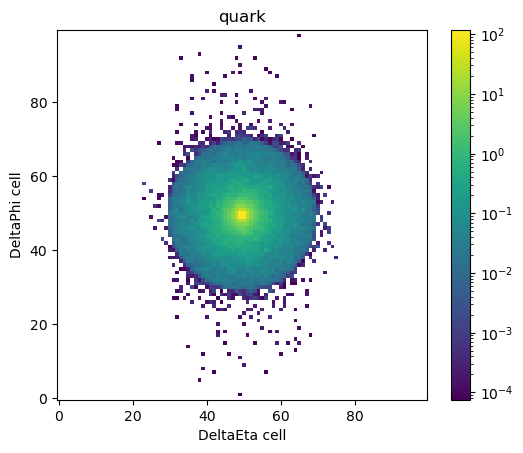

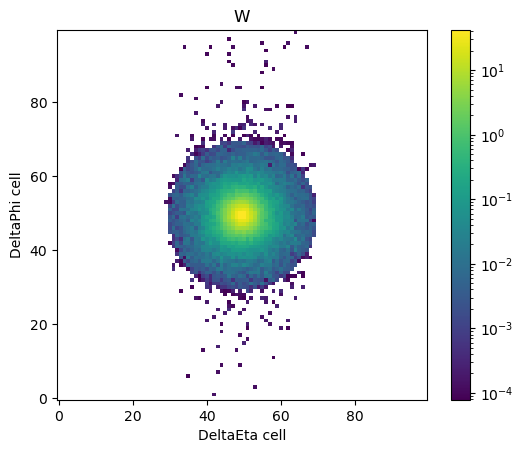

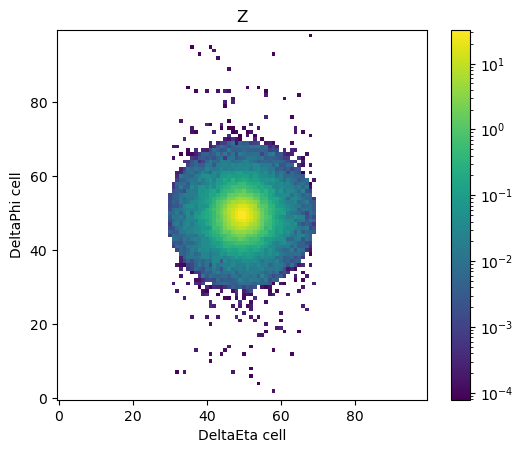

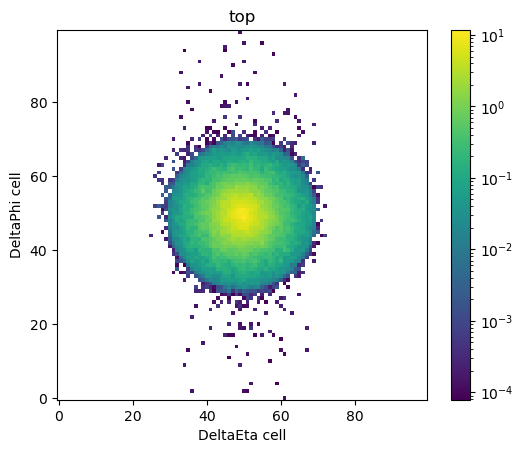

In [7]:
# plots of sum of jet images for different jet catagories
def plot_sum_images(jet_imgs,label,labels_str):
    image_g = jet_imgs[label==0]
    image_q = jet_imgs[label==1]
    image_W = jet_imgs[label==2]
    image_Z = jet_imgs[label==3]
    image_t = jet_imgs[label==4]
    images = [image_q, image_g, image_W, image_Z, image_t]

    for i in range(len(images)):
        SUM_Image = np.sum(images[i], axis = 0)
        plt.imshow(SUM_Image/float(images[i].shape[0]), origin='lower', norm=LogNorm())
        plt.colorbar()
        plt.title(labels_str[i])
        plt.xlabel('DeltaEta cell')
        plt.ylabel('DeltaPhi cell')
        plt.show()
plot_sum_images(jet_imgs_train,y_train,labels_str)